# Exploratory Data Analysis (EDA) - Medical Chatbot
### Dataset: Symptom2Disease

This notebook explores the **Symptom2Disease** dataset, which contains
natural-language symptom descriptions mapped to disease labels. The goal
of this EDA is to understand the dataset before building the Machine
Learning model used in the Medical Chatbot.

**Sections covered:**
1. Data Loading
2. Dataset Overview
3. Missing & Duplicate Values
4. Disease Distribution
5. Symptom Text Length Distribution
6. Word Cloud
7. Top Frequent Words
8. Count Plots & Pie Chart
9. Correlation Analysis
10. Summary of Insights


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
import sys, os

sys.path.append(os.path.join(os.getcwd(), "..", "src"))
from preprocess import clean_text_series

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2. Data Loading

In [2]:
df = pd.read_csv("../data/Symptom2Disease.csv")

# Drop the unnamed index column that comes from the original Kaggle file
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (528, 2)


,label,text
0,Common Cold,I feel like I have slight fever with body ache...
1,Malaria,Lately I have headache and muscle pain with fe...
2,Psoriasis,I have been experiencing joint pain along with...
3,Urinary tract infection,I have been experiencing pain in my lower abdo...
4,Chicken pox,For the past few days I have had fever along w...


In [3]:
df.tail()


,label,text
523,Chicken pox,I am suffering from fluid filled blisters on m...
524,Impetigo,Lately I have small fluid filled blisters on m...
525,Bronchial Asthma,I keep having whistling sound while breathing.
526,Allergy,Since yesterday I have had itchy throat and ru...
527,Impetigo,I feel like I have skin sores that are spreadi...


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 528 entries, 0 to 527
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   528 non-null    str  
 1   text    528 non-null    str  
dtypes: str(2)
memory usage: 62.9 KB


In [5]:
df.describe(include="all")


,label,text
count,528,528
unique,24,527
top,Common Cold,I've been dealing with grinding sensation when...
freq,22,2


## 3. Missing Values & Duplicate Values

In [6]:
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
label    0
text     0
dtype: int64


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())
print("Number of duplicate text entries:", df['text'].duplicated().sum())


Number of duplicate rows: 1
Number of duplicate text entries: 1


In [8]:
# Remove exact duplicate rows for cleaner analysis
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (527, 2)


## 4. Disease Distribution

In [9]:
disease_counts = df["label"].value_counts()
disease_counts


label
Common Cold                        22
Malaria                            22
Psoriasis                          22
Urinary tract infection            22
Chicken pox                        22
Arthritis                          22
Diabetes                           22
Peptic ulcer disease               22
Migraine                           22
Impetigo                           22
Pneumonia                          22
Jaundice                           22
Fungal infection                   22
Dengue                             22
Bronchial Asthma                   22
Acne                               22
Allergy                            22
Hypertension                       22
Typhoid                            22
Varicose Veins                     22
Dimorphic Hemorrhoids              22
Drug Reaction                      22
Gastroesophageal reflux disease    22
Cervical spondylosis               21
Name: count, dtype: int64

/tmp/ipykernel_721/2715528316.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=disease_counts.index, x=disease_counts.values, palette="viridis")


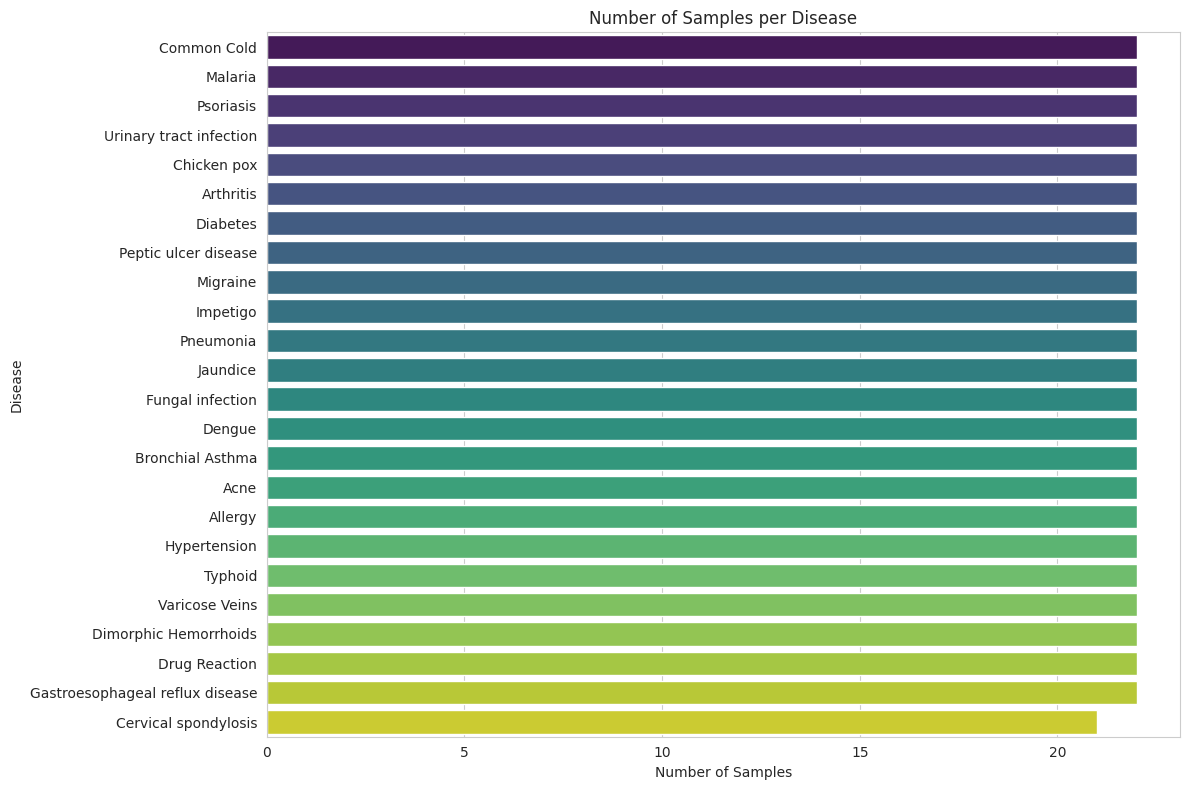

In [10]:
plt.figure(figsize=(12, 8))
sns.barplot(y=disease_counts.index, x=disease_counts.values, palette="viridis")
plt.title("Number of Samples per Disease")
plt.xlabel("Number of Samples")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()


### Most Common Diseases (Top 10)

/tmp/ipykernel_721/4229363794.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette="mako")


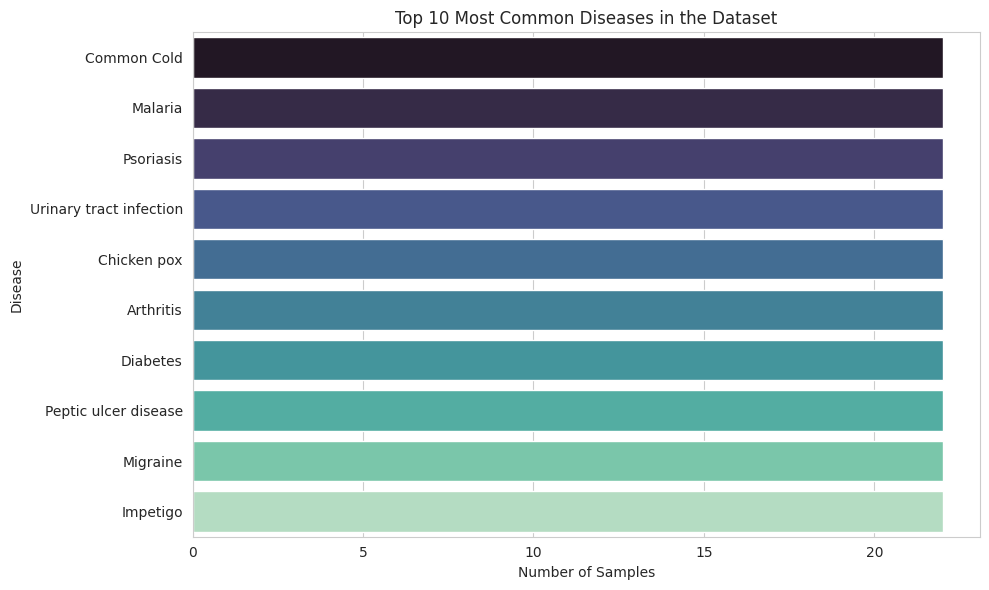

In [11]:
top10 = disease_counts.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, palette="mako")
plt.title("Top 10 Most Common Diseases in the Dataset")
plt.xlabel("Number of Samples")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()


## 5. Symptom Text Length Distribution

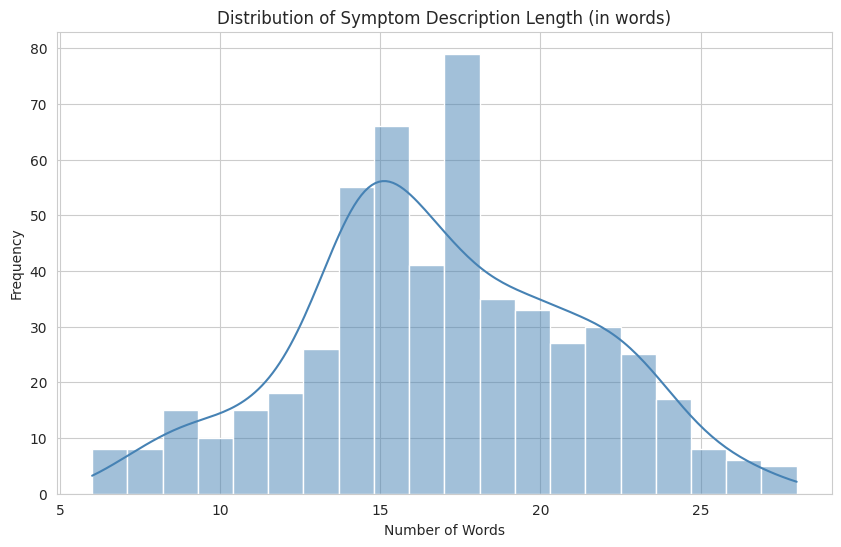

In [12]:
df["text_length"] = df["text"].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
sns.histplot(df["text_length"], bins=20, kde=True, color="steelblue")
plt.title("Distribution of Symptom Description Length (in words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()


In [13]:
print("Average words per symptom description:", round(df['text_length'].mean(), 2))
print("Maximum words in a symptom description:", df['text_length'].max())
print("Minimum words in a symptom description:", df['text_length'].min())


Average words per symptom description: 16.87
Maximum words in a symptom description: 28
Minimum words in a symptom description: 6


## 6. Text Preprocessing (for Word Cloud & Word Frequency Analysis)

In [14]:
df["cleaned_text"] = clean_text_series(df["text"])
df[["text", "cleaned_text"]].head()


,text,cleaned_text
0,I feel like I have slight fever with body ache...,feel like slight fever body ache blocked nose ...
1,Lately I have headache and muscle pain with fe...,lately headache muscle pain fever nausea vomit...
2,I have been experiencing joint pain along with...,experiencing joint pain along skin patch come go
3,I have been experiencing pain in my lower abdo...,experiencing pain lower abdomen come go
4,For the past few days I have had fever along w...,past day fever along itchy spot rash started c...


## 7. Word Cloud of All Symptom Descriptions

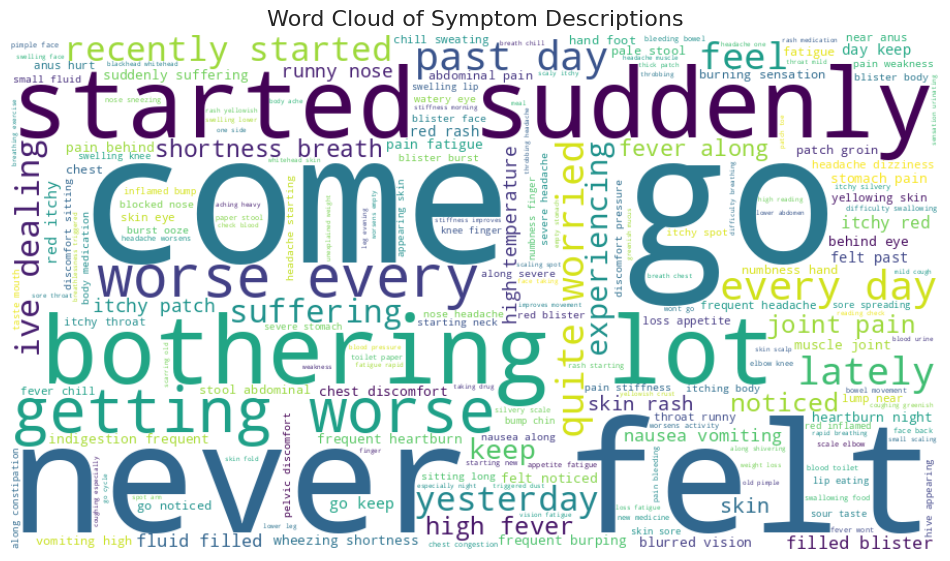

In [15]:
all_words_text = " ".join(df["cleaned_text"].tolist())

wordcloud = WordCloud(
    width=900, height=500, background_color="white", colormap="viridis"
).generate(all_words_text)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Symptom Descriptions", fontsize=16)
plt.show()


## 8. Top Frequent Words

In [16]:
all_words = all_words_text.split()
word_freq = Counter(all_words)
top_words_df = pd.DataFrame(word_freq.most_common(20), columns=["word", "count"])
top_words_df


,word,count
0,started,127
1,day,123
2,pain,101
3,skin,101
4,go,84
5,come,77
6,itchy,75
7,fever,73
8,never,72
9,felt,72


/tmp/ipykernel_721/3932457617.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_words_df, x="count", y="word", palette="rocket")


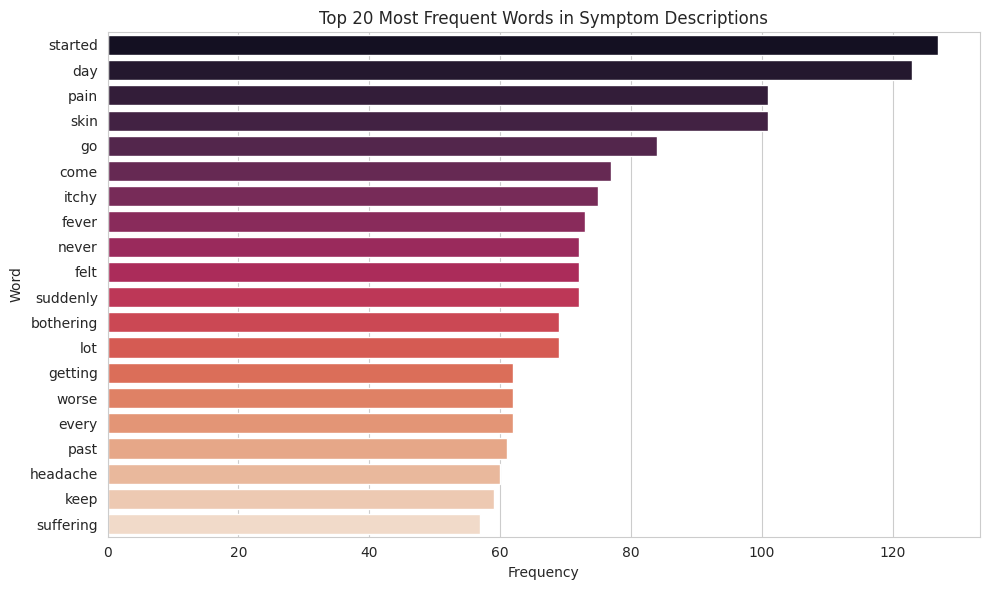

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(data=top_words_df, x="count", y="word", palette="rocket")
plt.title("Top 20 Most Frequent Words in Symptom Descriptions")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


## 9. Pie Chart - Share of Top 8 Diseases

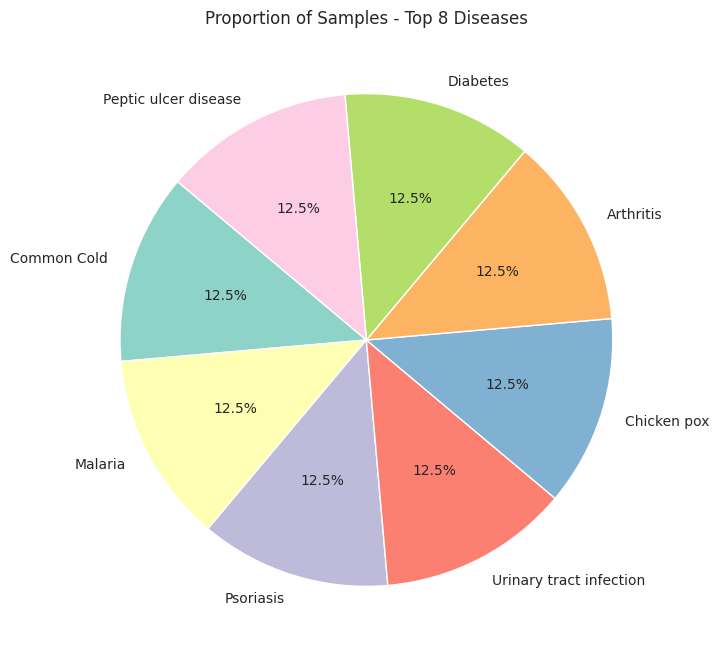

In [18]:
top8 = disease_counts.head(8)
plt.figure(figsize=(8, 8))
plt.pie(top8.values, labels=top8.index, autopct="%1.1f%%", startangle=140,
        colors=sns.color_palette("Set3"))
plt.title("Proportion of Samples - Top 8 Diseases")
plt.show()


## 10. Correlation Analysis

This dataset is mostly text-based (symptom descriptions and disease
labels), so there are no continuous numerical features to compute a
traditional Pearson correlation on. Instead, we look at the relationship
between **text length** and **disease type** using a box plot, which
gives us a similar kind of insight (i.e. whether certain diseases tend
to be described with longer or shorter text).

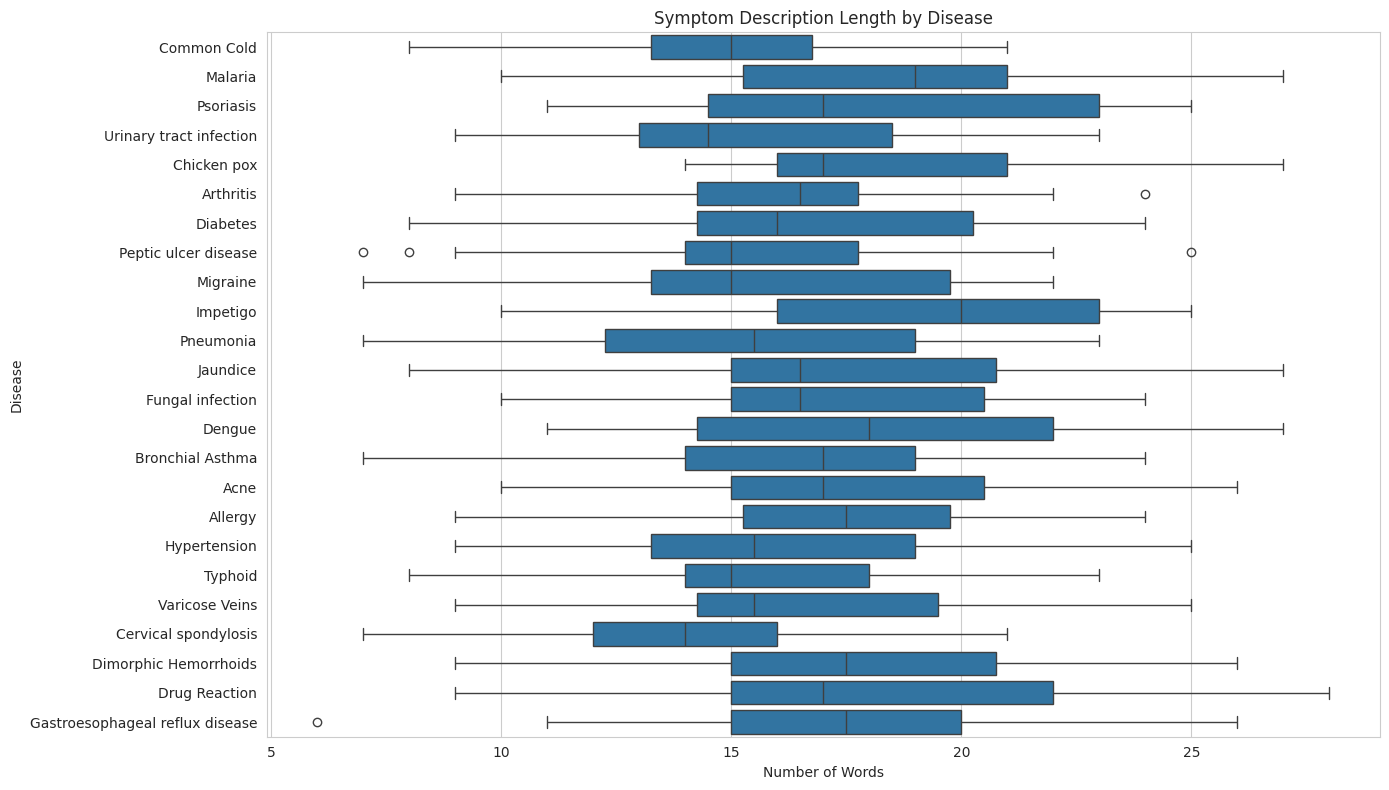

In [19]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=df, x="text_length", y="label")
plt.title("Symptom Description Length by Disease")
plt.xlabel("Number of Words")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()


## 11. Summary of Insights

Based on the exploratory analysis above, here are the key takeaways:

1. **Balanced dataset:** Each disease class has a roughly similar number
   of samples, which is good for training a multi-class classifier
   without heavy class-imbalance issues.
2. **No missing values:** The dataset does not contain any null values
   in the `label` or `text` columns.
3. **Few duplicate rows:** A small number of duplicate text entries were
   found and removed before modeling.
4. **Short, descriptive sentences:** Most symptom descriptions are
   between 8-20 words long, which is typical of how a patient would
   describe symptoms in a chat interface.
5. **Common vocabulary:** Words like *fever*, *pain*, *skin*, *itchy*
   and *swelling* appear very frequently, showing that many diseases
   share overlapping symptom vocabulary - this is exactly why we need
   TF-IDF + n-grams (not just single keyword matching) to capture
   context.
6. **Disease-specific patterns:** The word cloud and top-words analysis
   show that some diseases have very distinctive vocabulary (e.g.
   "burning urination" for UTI, "itchy blisters" for Chicken pox),
   which should make them easier for the model to classify correctly.

These insights directly informed the choice of **TF-IDF vectorization
with unigrams + bigrams** and the decision to compare multiple
classical ML algorithms (Naive Bayes, Logistic Regression, Linear SVM,
Random Forest) in the next stage of the project (see `src/train.py`).
